In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from pathlib import Path


## Data Reading

In [19]:
# Dataset path
BASE_DIR = Path.cwd()
file_path = BASE_DIR / "column_2C.dat"

# 2. Column names
columns = [
    "pelvic_incidence",
    "pelvic_tilt",
    "lumbar_lordosis_angle",
    "sacral_slope",
    "pelvic_radius",
    "degree_spondylolisthesis",
    "class"
]

# data reading
df = pd.read_csv(
    file_path,
    sep=r"\s+",     #以一個或多個空白字元分隔欄位
    header=None,    #沒有標題列
    names=columns   #手動指定七個欄位名稱
)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types:")
display(df.dtypes)


Dataset Shape: (310, 7)

First 5 Rows:


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.03,22.55,39.61,40.48,98.67,-0.25,AB
1,39.06,10.06,25.02,29.00,114.41,4.56,AB
2,68.83,22.22,50.09,46.61,105.99,-3.53,AB
3,69.30,24.65,44.31,44.64,101.87,11.21,AB
4,49.71,9.65,28.32,40.06,108.17,7.92,AB



Data Types:


pelvic_incidence            float64
pelvic_tilt                 float64
lumbar_lordosis_angle       float64
sacral_slope                float64
pelvic_radius               float64
degree_spondylolisthesis    float64
class                           str
dtype: object

### Observation of data

In [13]:
#duplicate observations
duplicate_count = df.duplicated().sum()
print("Number of duplicated rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Number of duplicated rows: 0
Duplicate percentage: 0.0 %


In [14]:
# Missing values
print("\nMissing Values:")
print(df.isna().sum())


Missing Values:
pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
class                       0
dtype: int64


In [11]:
# Check variable ranges
print("\nVariable Ranges:")
display(pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique": df.nunique()
}))


Variable Ranges:


,Min,Max,Unique
pelvic_incidence,26.15,129.83,301
pelvic_tilt,-6.55,49.43,291
lumbar_lordosis_angle,14.0,125.74,271
sacral_slope,13.37,121.43,276
pelvic_radius,70.08,163.07,303
degree_spondylolisthesis,-11.06,418.54,305
class,AB,NO,2


##### Target distribution

In [18]:
# Target distribution
# 了解 Y = 0/1 的比例
print(df["class"].value_counts())

print("\nTarget percentage:")
print(
    df["class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class
AB    210
NO    100
Name: count, dtype: int64

Target percentage:
class
AB    67.74
NO    32.26
Name: proportion, dtype: float64


#### outlier detection

整體 Boxplot 顯示部分生物力學變數存在極端觀測值。我們進一步依診斷類別比較資料分布，觀察這些極端值是否集中於異常組，以及它們是否反映不同群體之間的分布差異，而非單純的資料錯誤。

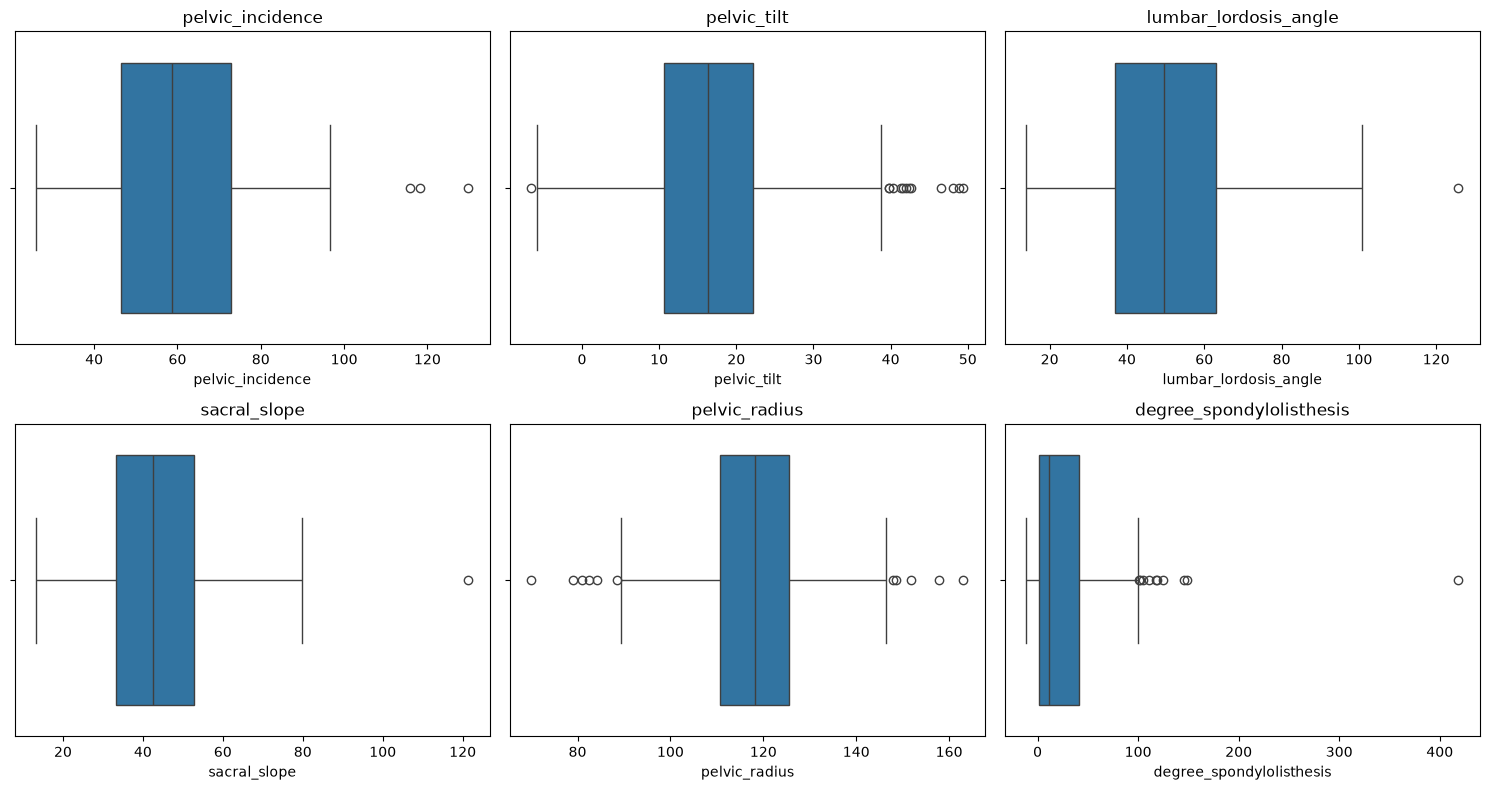

In [ ]:
# 整體資料分布：IQR Method & boxplot

numeric_cols = df.select_dtypes(include="number").columns

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(data=df, x=col, ax=ax)  # y=col 改成 x=col
    ax.set_title(col)

plt.tight_layout()
plt.show()

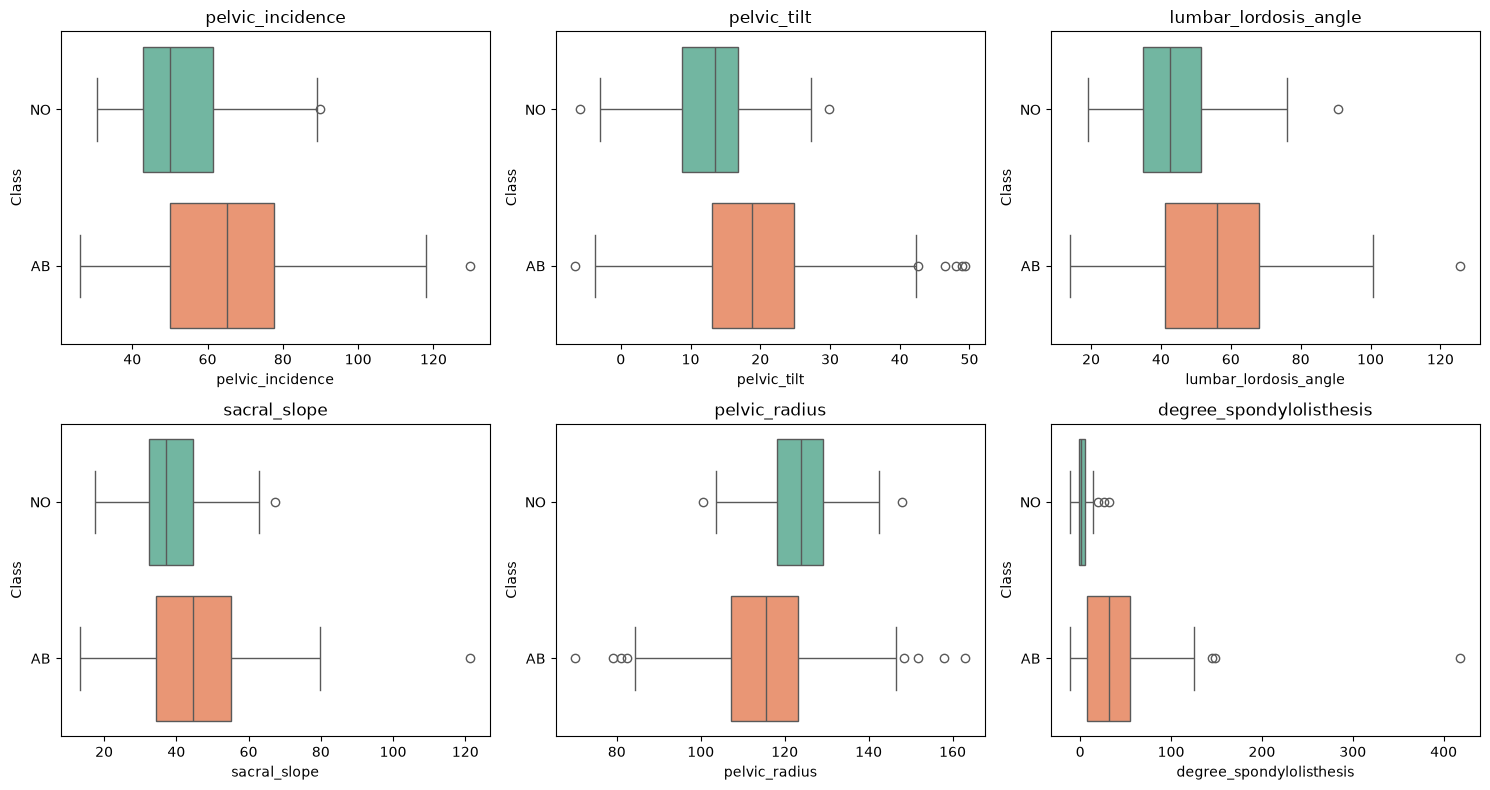

In [ ]:
# Normal / Abnormal分組比較資料分布：IQR Method & boxplot

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(
        data=df,
        x=col,
        y="class",
        hue="class",
        order=["NO", "AB"],
        hue_order=["NO", "AB"],
        palette="Set2",
        legend=False,
        ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("Class")

plt.tight_layout()
plt.show()
